# Polynomial regression

A comparison of polynomial degree, validation error and sensitivity to an endpoint observation.

## Data and scope

The analysis uses 18 pairs of time-of-day and vehicle-speed observations, defined directly in the code. Time values range from 1 to 22; speed units are unspecified. No external data file is required.

## Environment

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
print('numpy', np.__version__, 'pandas', pd.__version__, 'scipy', scipy.__version__, 'sklearn', sklearn.__version__)
results = {}

numpy 2.4.4 pandas 3.0.2 scipy 1.17.1 sklearn 1.8.0


## Baseline analysis

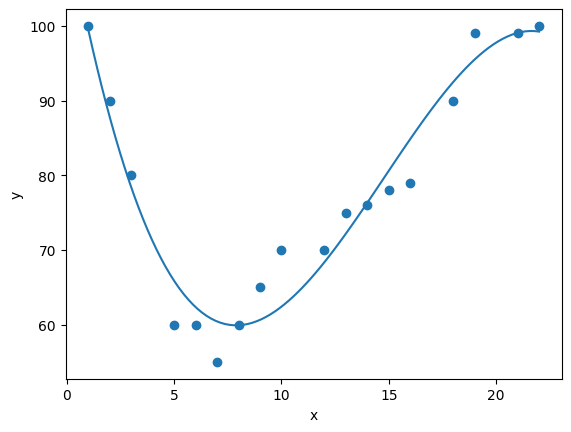

In [2]:
import numpy
import matplotlib.pyplot as plt
x = [1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 18, 19, 21, 22]
y = [100, 90, 80, 60, 60, 55, 60, 65, 70, 70, 75, 76, 78, 79, 90, 99, 99, 100]
mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))
myline = numpy.linspace(1, 22, 100)
plt.scatter(x, y)
plt.plot(myline, mymodel(myline))
plt.show()

In [3]:
import numpy
from sklearn.metrics import r2_score
x = [1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 18, 19, 21, 22]
y = [100, 90, 80, 60, 60, 55, 60, 65, 70, 70, 75, 76, 78, 79, 90, 99, 99, 100]
mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))
print(r2_score(y, mymodel(x)))

0.9432150416451026


In [4]:
import numpy
from sklearn.metrics import r2_score
x = [1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 18, 19, 21, 22]
y = [100, 90, 80, 60, 60, 55, 60, 65, 70, 70, 75, 76, 78, 79, 90, 99, 99, 100]
mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))
speed = mymodel(17)
print(speed)

88.87331269698001


## Sensitivity analysis

Polynomials of degrees 1, 2, 3 and 5 are fitted to the same observations. Leave-one-out validation refits each model on 17 points and predicts the omitted observation. A separate sensitivity check changes the final speed from 100 to 140 and refits the cubic. Predictions at x = 30 are mathematical extrapolation checks, not time-of-day forecasts.

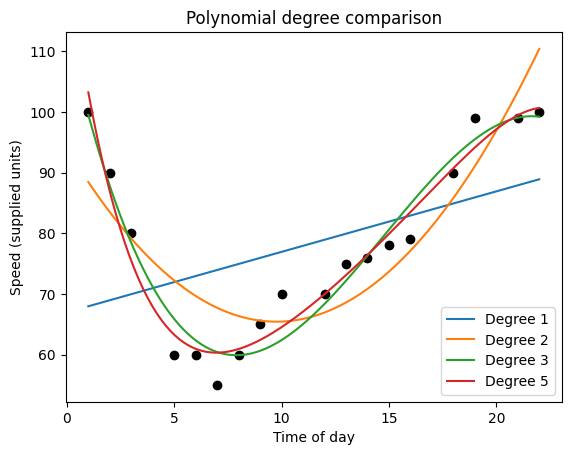

In [5]:
from scipy.stats import pearsonr, linregress
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
x = np.array([1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 18, 19, 21, 22])
y = np.array([100, 90, 80, 60, 60, 55, 60, 65, 70, 70, 75, 76, 78, 79, 90, 99, 99, 100])
results['polynomial'] = {}
fig, ax = plt.subplots()
ax.scatter(x, y, color='black')
grid = np.linspace(1, 22, 200)
for degree in [1, 2, 3, 5]:
    m = np.poly1d(np.polyfit(x, y, degree))
    cv = cross_val_predict(make_pipeline(PolynomialFeatures(degree), LinearRegression()), x.reshape(-1, 1), y, cv=LeaveOneOut())
    results['polynomial'][str(degree)] = {'r2': float(r2_score(y, m(x))), 'prediction17': float(m(17)), 'prediction30': float(m(30)), 'loocv_rmse': float(np.sqrt(mean_squared_error(y, cv)))}
    ax.plot(grid, m(grid), label='Degree ' + str(degree))
ax.legend()
ax.set(xlabel='Time of day', ylabel='Speed (supplied units)', title='Polynomial degree comparison')
plt.show()
changed = y.copy()
changed[-1] = 140
m = np.poly1d(np.polyfit(x, changed, 3))
results['polynomial']['last speed100 to140'] = {'r2': float(r2_score(changed, m(x))), 'prediction17': float(m(17)), 'prediction30': float(m(30))}

## Results

R² values describe training fit. Where reported, leave-one-out RMSE measures held-out error in response units; lower values indicate smaller errors.

In [6]:
display(pd.DataFrame.from_dict(results['polynomial'], orient='index').rename(columns={'r2':'Training R²','prediction17':'Prediction at 17','prediction30':'Extrapolation at 30','loocv_rmse':'Leave-one-out RMSE'}).round(4).fillna('Not evaluated'))

,Training R²,Prediction at 17,Extrapolation at 30,Leave-one-out RMSE
1,0.1823,83.9297,96.8968,15.7576
2,0.7598,81.1757,188.4271,9.437
3,0.9432,88.8733,37.9539,4.2348
5,0.9568,87.1374,-20.7985,6.391
last speed100 to140,0.8701,88.8018,178.6810,Not evaluated


## Interpretation and limitations

The cubic achieves the lowest leave-one-out RMSE of the tested degrees (4.2348). Degree five improves training R² to 0.9568 but increases validation error to 6.3910. Changing the endpoint has little effect on the cubic prediction at 17, yet changes the extrapolated value at 30 from 37.9539 to 178.6810. Model complexity and extrapolation therefore require separate scrutiny. Selecting a degree using these validation results also means that an independent test set would be needed for a final performance estimate.

## Reproducibility

Cells were executed sequentially in an independent Python namespace. Outputs and plots are embedded, and library versions are recorded above. Analysis and editorial preparation used AI assistance.